# Task 3: Marketing Funnel & Conversion Performance Analysis

**Dataset:** synthetic demonstration data created for this internship project. It does not represent a real company.

## 1. Import libraries and upload dataset

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()  # Upload marketing_funnel.csv
df = pd.read_csv('marketing_funnel.csv', parse_dates=['LeadDate'])
df.head()

Saving marketing_funnel.csv to marketing_funnel (1).csv


,LeadID,LeadDate,Channel,Campaign,Device,Region,LandingPageVisited,FormSubmitted,QualifiedLead,DemoScheduled,Converted,MarketingSpend,Revenue
0,10001,2025-02-02,Organic Search,Comparison Pages,Mobile,East,1,0,0,0,0,9.53,0.00
1,10002,2025-10-10,Email,Re-engagement,Mobile,North,1,0,0,0,0,40.89,0.00
2,10003,2025-08-27,Paid Search,Brand Search,Mobile,South,1,0,0,0,0,155.23,0.00
3,10004,2025-06-10,Referral,Partner Referral,Tablet,West,1,1,1,1,1,50.13,1912.64
4,10005,2025-06-08,Paid Search,Brand Search,Mobile,West,1,1,0,0,0,143.65,0.00


## 2. Data inspection and cleaning

In [6]:
print('Shape:', df.shape)
print(df.info())
print('Missing values:\n', df.isnull().sum())
print('Duplicate LeadIDs:', df['LeadID'].duplicated().sum())
df = df.drop_duplicates(subset='LeadID').copy()
df = df.dropna(subset=['LeadID','Channel','LeadDate'])
for col in ['LandingPageVisited','FormSubmitted','QualifiedLead','DemoScheduled','Converted']:
    df[col] = df[col].fillna(0).astype(int)
df.head()

Shape: (6000, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   LeadID              6000 non-null   int64         
 1   LeadDate            6000 non-null   datetime64[ns]
 2   Channel             6000 non-null   object        
 3   Campaign            6000 non-null   object        
 4   Device              6000 non-null   object        
 5   Region              6000 non-null   object        
 6   LandingPageVisited  6000 non-null   int64         
 7   FormSubmitted       6000 non-null   int64         
 8   QualifiedLead       6000 non-null   int64         
 9   DemoScheduled       6000 non-null   int64         
 10  Converted           6000 non-null   int64         
 11  MarketingSpend      6000 non-null   float64       
 12  Revenue             6000 non-null   float64       
dtypes: datetime64[ns](1), float64(

,LeadID,LeadDate,Channel,Campaign,Device,Region,LandingPageVisited,FormSubmitted,QualifiedLead,DemoScheduled,Converted,MarketingSpend,Revenue
0,10001,2025-02-02,Organic Search,Comparison Pages,Mobile,East,1,0,0,0,0,9.53,0.00
1,10002,2025-10-10,Email,Re-engagement,Mobile,North,1,0,0,0,0,40.89,0.00
2,10003,2025-08-27,Paid Search,Brand Search,Mobile,South,1,0,0,0,0,155.23,0.00
3,10004,2025-06-10,Referral,Partner Referral,Tablet,West,1,1,1,1,1,50.13,1912.64
4,10005,2025-06-08,Paid Search,Brand Search,Mobile,West,1,1,0,0,0,143.65,0.00


## 3. Overall funnel analysis

In [8]:
stages = [('Leads',len(df)),('Landing Page Visits',df.LandingPageVisited.sum()),('Form Submissions',df.FormSubmitted.sum()),('Qualified Leads',df.QualifiedLead.sum()),('Demos Scheduled',df.DemoScheduled.sum()),('Conversions',df.Converted.sum())]
funnel = pd.DataFrame(stages, columns=['Stage','Count'])
funnel['Conversion from previous (%)'] = [100] + [funnel.loc[i,'Count']/funnel.loc[i-1,'Count']*100 if funnel.loc[i-1,'Count'] else 0 for i in range(1,len(funnel))]
funnel['Conversion from leads (%)'] = funnel['Count']/len(df)*100
funnel

,Stage,Count,Conversion from previous (%),Conversion from leads (%)
0,Leads,6000,100.000000,100.000000
1,Landing Page Visits,5004,83.400000,83.400000
2,Form Submissions,1457,29.116707,24.283333
3,Qualified Leads,840,57.652711,14.000000
4,Demos Scheduled,412,49.047619,6.866667
5,Conversions,145,35.194175,2.416667


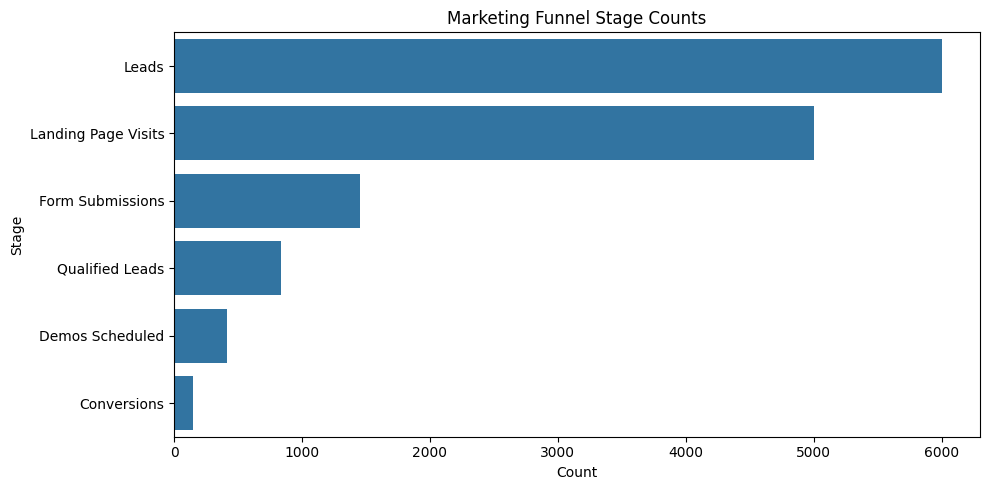

In [9]:
plt.figure(figsize=(10,5))
sns.barplot(data=funnel, x='Count', y='Stage')
plt.title('Marketing Funnel Stage Counts')
plt.tight_layout()
plt.show()

## 4. Channel performance

In [10]:
channel = df.groupby('Channel').agg(Leads=('LeadID','count'), Visits=('LandingPageVisited','sum'), Forms=('FormSubmitted','sum'), Qualified=('QualifiedLead','sum'), Demos=('DemoScheduled','sum'), Conversions=('Converted','sum'), Spend=('MarketingSpend','sum'), Revenue=('Revenue','sum')).reset_index()
channel['Conversion Rate (%)'] = channel.Conversions/channel.Leads*100
channel['Cost per Lead'] = channel.Spend/channel.Leads
channel['CPA'] = channel.Spend/channel.Conversions.replace(0,np.nan)
channel['ROAS'] = channel.Revenue/channel.Spend
channel.sort_values('Conversion Rate (%)', ascending=False).round(2)

,Channel,Leads,Visits,Forms,Qualified,Demos,Conversions,Spend,Revenue,Conversion Rate (%),Cost per Lead,CPA,ROAS
3,Referral,793,715,293,204,118,57,30058.44,103197.33,7.19,37.90,527.34,3.43
0,Email,969,882,285,180,85,34,23586.53,60170.66,3.51,24.34,693.72,2.55
2,Paid Search,1514,1327,415,242,112,27,220010.96,48833.73,1.78,145.32,8148.55,0.22
1,Organic Search,1274,1065,293,142,62,17,23583.62,30743.22,1.33,18.51,1387.27,1.30
4,Social Media,1450,1015,171,72,35,10,133556.30,17553.20,0.69,92.11,13355.63,0.13


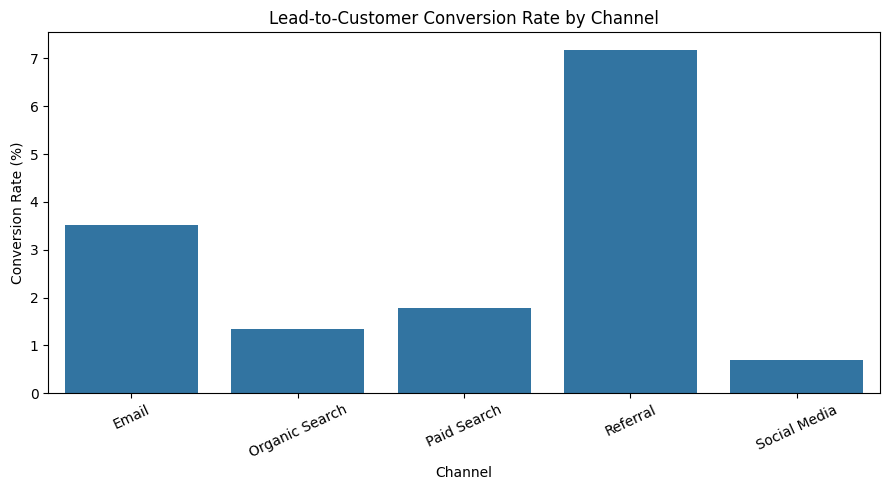

In [11]:
plt.figure(figsize=(9,5))
sns.barplot(data=channel, x='Channel', y='Conversion Rate (%)')
plt.xticks(rotation=25)
plt.title('Lead-to-Customer Conversion Rate by Channel')
plt.tight_layout()
plt.show()

## 5. Campaign and device analysis

In [12]:
campaign = df.groupby('Campaign').agg(Leads=('LeadID','count'), Conversions=('Converted','sum'), Spend=('MarketingSpend','sum'), Revenue=('Revenue','sum')).reset_index()
campaign['Conversion Rate (%)'] = campaign.Conversions/campaign.Leads*100
campaign['CPA'] = campaign.Spend/campaign.Conversions.replace(0,np.nan)
campaign['ROAS'] = campaign.Revenue/campaign.Spend
campaign.sort_values('Conversion Rate (%)', ascending=False).round(2)

,Campaign,Leads,Conversions,Spend,Revenue,Conversion Rate (%),CPA,ROAS
4,Customer Referral,260,26,10180.26,47637.74,10.00,391.55,4.68
9,Partner Referral,243,18,8867.37,31398.27,7.41,492.63,3.54
0,Affiliate,290,13,11010.81,24161.32,4.48,846.99,2.19
13,Re-engagement,332,13,8292.48,22394.64,3.92,637.88,2.70
8,Newsletter,325,11,7356.70,19195.70,3.38,668.79,2.61
11,Product Launch,312,10,7937.35,18580.32,3.21,793.74,2.34
12,Product Pages,416,9,7979.18,15834.04,2.16,886.58,1.98
3,Competitor Keywords,509,10,74004.25,18736.73,1.96,7400.42,0.25
1,Brand Search,479,9,69764.40,14091.89,1.88,7751.60,0.20
10,Product Keywords,526,8,76242.31,16005.11,1.52,9530.29,0.21


In [13]:
device = df.groupby('Device').agg(Leads=('LeadID','count'), Conversions=('Converted','sum')).reset_index()
device['Conversion Rate (%)'] = device.Conversions/device.Leads*100
device

,Device,Leads,Conversions,Conversion Rate (%)
0,Desktop,2195,54,2.460137
1,Mobile,3434,79,2.300524
2,Tablet,371,12,3.234501


## 6. Monthly trend

In [14]:
df['Month'] = df['LeadDate'].dt.to_period('M').astype(str)
monthly = df.groupby('Month').agg(Leads=('LeadID','count'), Conversions=('Converted','sum'), Spend=('MarketingSpend','sum'), Revenue=('Revenue','sum')).reset_index()
monthly['Conversion Rate (%)'] = monthly.Conversions/monthly.Leads*100
monthly.head()

,Month,Leads,Conversions,Spend,Revenue,Conversion Rate (%)
0,2025-01,469,8,32665.09,14177.89,1.705757
1,2025-02,503,7,35824.28,13578.89,1.391650
2,2025-03,519,10,38413.91,17231.25,1.926782
3,2025-04,503,5,35555.94,8778.46,0.994036
4,2025-05,492,15,35013.55,28319.26,3.048780


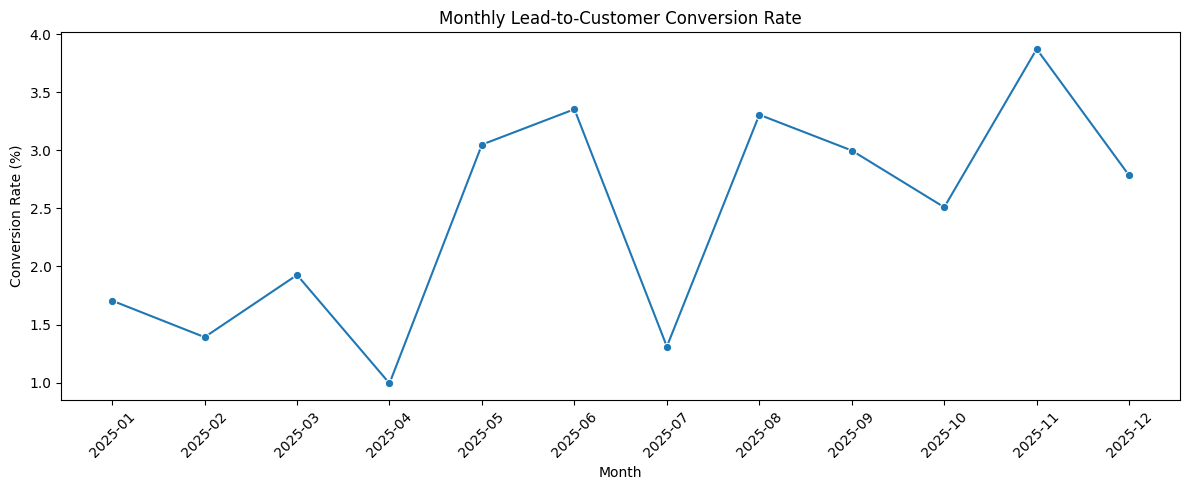

In [15]:
plt.figure(figsize=(12,5))
sns.lineplot(data=monthly, x='Month', y='Conversion Rate (%)', marker='o')
plt.xticks(rotation=45)
plt.title('Monthly Lead-to-Customer Conversion Rate')
plt.tight_layout()
plt.show()

## 7. Key metrics and recommendations

- Lead-to-customer conversion rate = customers / total leads × 100.
- Cost per lead (CPL) = marketing spend / leads.
- Cost per acquisition (CPA) = marketing spend / converted customers.
- Return on ad spend (ROAS) = attributed revenue / marketing spend.
- Review stage-level drop-offs to identify where prospects leave the funnel.
- Compare channel conversion, CPA and ROAS together before reallocating budget.
- Improve landing-page clarity and form usability where visit-to-form conversion is weak.
- Test follow-up timing and qualification criteria; validate changes with controlled experiments.

**Caution:** The data is synthetic. Results demonstrate analysis methods, not actual marketing performance.

In [16]:
print('Total leads:', len(df))
print('Conversions:', int(df.Converted.sum()))
print('Overall conversion rate (%):', round(df.Converted.mean()*100,2))
print('Total spend:', round(df.MarketingSpend.sum(),2))
print('Total revenue:', round(df.Revenue.sum(),2))
print('Overall ROAS:', round(df.Revenue.sum()/df.MarketingSpend.sum(),2))
files.download('marketing_funnel.csv')  # optional: download original uploaded file

Total leads: 6000
Conversions: 145
Overall conversion rate (%): 2.42
Total spend: 430795.85
Total revenue: 260498.14
Overall ROAS: 0.6


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>